In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib as plt 


#dataset load krwane mai help karegi
from datasets import load_dataset

c:\Users\hp\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
emotion_dataset  = load_dataset('dair-ai/emotion')
train_text       = emotion_dataset['train']['text']
train_label      = emotion_dataset['train']['label']

test_text        = emotion_dataset['test']['text']
test_label       = emotion_dataset['test']['label']

In [3]:
label_name = emotion_dataset['train'].features['label'].names

In [4]:
df_train = pd.DataFrame(
    {
        'text' : train_text,
        'label': [label_name[i] for i in train_label]
    }
)

df_text = pd.DataFrame(
    {
        'text' : test_text,
        'label': [label_name[i] for i in test_label]
    }
)


<Axes: xlabel='label', ylabel='count'>

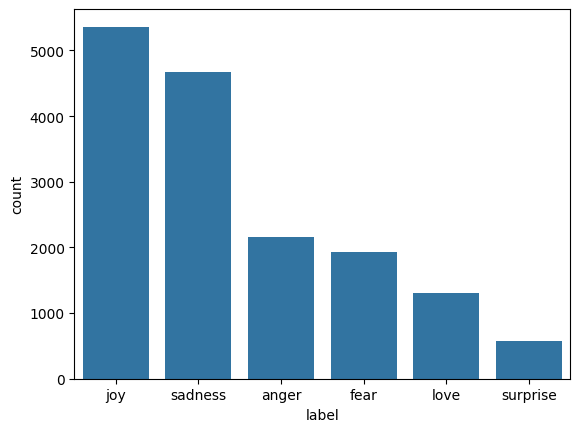

In [5]:
sns.countplot(x='label', data=df_train, order=df_train['label'].value_counts().index)

In [6]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_word = 10000

tokenizer = Tokenizer(num_words=max_word, oov_token='<unk>')
tokenizer.fit_on_texts(df_train['text'])

train_sequnce = tokenizer.texts_to_sequences(df_train['text'])
text_sequence = tokenizer.texts_to_sequences(df_text['text'])

padded_train_sequence = pad_sequences(train_sequnce, maxlen=50, padding='post', truncating='post')
padded_text_sequence = pad_sequences(text_sequence, maxlen=50, padding='post', truncating='post')

train_labels = np.array(train_label)
text_lables = np.array(test_label)

num_classes = len(np.unique(train_labels))
num_classes

print(f"vocabulary size: { len(tokenizer.word_index)}")
print(f"max sentence length : {padded_train_sequence.shape[1]}")

vocabulary size: 15213
max sentence length : 50


In [7]:
from sklearn.utils import class_weight

class_weights    = class_weight.compute_class_weight(
    class_weight ='balanced',
    classes      = np.unique(train_labels),
    y            = train_labels
)

class_weights_dict = dict(enumerate(class_weights))

In [8]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [9]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Embedding, Dense, Dropout, LSTM, GRU

rnn_model = Sequential([
    Embedding(input_dim = max_word, output_dim = 128 , input_length = 50),
    SimpleRNN(units=128, return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

rnn_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

c:\Users\hp\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [10]:
rnn_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_text_sequence, text_lables),
    epochs = 20,
    batch_size=32,
    class_weight=class_weights_dict,
    callbacks=[early_stopping]
)

rnn_loss, rnn_accuracy = rnn_model.evaluate(padded_text_sequence, text_lables)
print(f"RNN Loss: {rnn_loss}")
print(f"RNN Accuracy: {rnn_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 94s 177ms/step - accuracy: 0.1489 - loss: 2.0717 - val_accuracy: 0.1360 - val_loss: 1.7602
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 85s 61ms/step - accuracy: 0.1346 - loss: 1.8913 - val_accuracy: 0.2495 - val_loss: 1.7854
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 30s 61ms/step - accuracy: 0.1262 - loss: 1.8314 - val_accuracy: 0.0995 - val_loss: 1.7930
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 29s 58ms/step - accuracy: 0.1288 - loss: 1.8086 - val_accuracy: 0.1295 - val_loss: 1.8064
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.1360 - loss: 1.7602
RNN Loss: 1.7602009773254395
RNN Accuracy: 0.13600000739097595


In [11]:
lstm_model = Sequential([
    Embedding(input_dim = max_word, output_dim = 128 , input_length = 50),
    LSTM(units=128, return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

lstm_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])


lstm_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_text_sequence, text_lables),
    epochs = 20,
    batch_size=32,
    class_weight=class_weights_dict,
    callbacks=[early_stopping]
)

lstm_loss, lstm_accuracy = lstm_model.evaluate(padded_text_sequence, text_lables)
print(f"LSTM Loss: {lstm_loss}")
print(f"LSTM Accuracy: {lstm_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 58s 104ms/step - accuracy: 0.1446 - loss: 1.7955 - val_accuracy: 0.0795 - val_loss: 1.7981
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 82s 104ms/step - accuracy: 0.1474 - loss: 1.7940 - val_accuracy: 0.1355 - val_loss: 1.8005
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 63s 126ms/step - accuracy: 0.1620 - loss: 1.7934 - val_accuracy: 0.0795 - val_loss: 1.7938
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 72s 105ms/step - accuracy: 0.1431 - loss: 1.7896 - val_accuracy: 0.0840 - val_loss: 1.8154
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 54s 107ms/step - accuracy: 0.1759 - loss: 1.7327 - val_accuracy: 0.1815 - val_loss: 1.7418
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 52s 104ms/step - accuracy: 0.3203 - loss: 1.4873 - val_accuracy: 0.2345 - val_loss: 1.6312
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 52s 104ms/step - accuracy: 0.5261 - loss: 0.9873 - val_accuracy: 0.7290 - val_loss: 0.8444
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 54s 107ms/step - accuracy: 0.7600 - loss: 0

In [12]:
gru_model = Sequential([
    Embedding(input_dim = max_word, output_dim = 128 , input_length = 50),
    GRU(units=128, return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

gru_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])


gru_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_text_sequence, text_lables),
    epochs = 20,
    batch_size=32,
    class_weight=class_weights_dict,
    callbacks=[early_stopping]
)

gru_loss, gru_accuracy = gru_model.evaluate(padded_text_sequence, text_lables)
print(f"GRU Loss: {gru_loss}")
print(f"GRU Accuracy: {gru_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 53s 94ms/step - accuracy: 0.1620 - loss: 1.7967 - val_accuracy: 0.0330 - val_loss: 1.8091
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 47s 95ms/step - accuracy: 0.1507 - loss: 1.7952 - val_accuracy: 0.0350 - val_loss: 1.7867
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 48s 96ms/step - accuracy: 0.1605 - loss: 1.7940 - val_accuracy: 0.3460 - val_loss: 1.7752
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 47s 93ms/step - accuracy: 0.1544 - loss: 1.7937 - val_accuracy: 0.2940 - val_loss: 1.7634
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 47s 93ms/step - accuracy: 0.1814 - loss: 1.7900 - val_accuracy: 0.0830 - val_loss: 1.8077
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 47s 94ms/step - accuracy: 0.1811 - loss: 1.7829 - val_accuracy: 0.3350 - val_loss: 1.7518
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 46s 92ms/step - accuracy: 0.1877 - loss: 1.7584 - val_accuracy: 0.1475 - val_loss: 1.8060
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 46s 93ms/step - accuracy: 0.2341 - loss: 1.7127 - 

In [13]:
result_df = pd.DataFrame({
    'Model' : ['RNN', 'LSTM', 'GRU'],
    'Test Loss': [rnn_loss, lstm_loss, gru_loss],
    'Test Accuracy': [rnn_accuracy, lstm_accuracy, gru_accuracy]
    }).sort_values(by='Test Accuracy',ascending=False)
result_df

,Model,Test Loss,Test Accuracy
1,LSTM,0.468026,0.872
2,GRU,1.751847,0.335
0,RNN,1.760201,0.136


In [14]:
from tensorflow.keras.layers import Bidirectional

BiGRU = Sequential([
     Embedding(input_dim = max_word, output_dim = 300 , input_length = 50),
     Bidirectional(GRU(128, return_sequences=True)),
     Dropout(0.5),
     Bidirectional(GRU(64)),
     Dropout(0.5),
     Dense(num_classes, activation='softmax')    
])

BiGRU.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

BiGRU.summary()

c:\Users\hp\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [15]:
BiGRU.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_text_sequence, text_lables),
    epochs = 20,
    batch_size=32,
    class_weight=class_weights_dict,
    callbacks=[early_stopping]
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 135s 247ms/step - accuracy: 0.6001 - loss: 1.0100 - val_accuracy: 0.8910 - val_loss: 0.3490
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 130s 260ms/step - accuracy: 0.9190 - loss: 0.2422 - val_accuracy: 0.9160 - val_loss: 0.2163
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 103s 206ms/step - accuracy: 0.9463 - loss: 0.1470 - val_accuracy: 0.9185 - val_loss: 0.2317
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 95s 189ms/step - accuracy: 0.9611 - loss: 0.1063 - val_accuracy: 0.9135 - val_loss: 0.2803
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 85s 170ms/step - accuracy: 0.9717 - loss: 0.0813 - val_accuracy: 0.9205 - val_loss: 0.2508


63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 55ms/step


<Axes: >

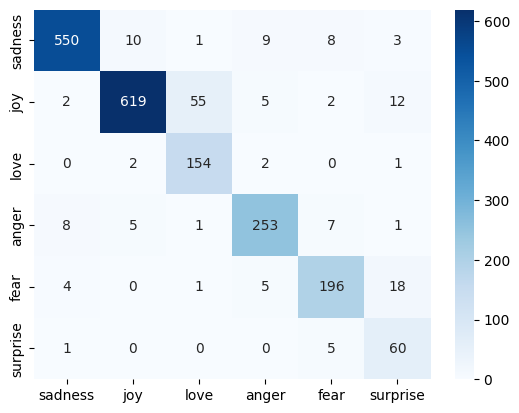

In [16]:
from sklearn.metrics import confusion_matrix

BiGRU_predictions = np.argmax(BiGRU.predict(padded_text_sequence),axis=1)

sns.heatmap(confusion_matrix(test_label, BiGRU_predictions),annot=True, fmt='d', cmap='Blues', xticklabels=label_name, yticklabels=label_name)
#

In [17]:
sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences = pad_sequences(sample_sequences, maxlen=50, padding='post', truncating='post')

sample_predictions = np.argmax(BiGRU.predict(sample_padded_sequences), axis=1)

for i in range(len(sample_texts)):
  print(f'Text: {sample_texts[i]}\nPredicted Emotion: {label_name[sample_predictions[i]]}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step
Text: I can't believe how happy I am right now, this is amazing!
Predicted Emotion: joy
Text: I feel so alone and hopeless today.
Predicted Emotion: sadness
Text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger
Text: I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear
Text: I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise


In [20]:
import os
import pickle

model_dir = 'Artifacts'
os.makedirs(model_dir, exist_ok=True) #yeh folder hai jiske andar sari exported file aane wali hai

#Save our BiGRU Model
BiGRU.save(os.path.join(model_dir, 'BiGRU_Modle.keras'))

#Save the tokenizer model
with open(os.path.join(model_dir, 'tokenizer.pkl'), 'wb') as file:
  pickle.dump(tokenizer, file)